# BlinkIt Grocery Sales Analysis

In [1]:
# Importing Required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Pre-Processing the Data: Cleaning, Duplicate Removal, Null Values checking

In [2]:
df = pd.read_excel("BlinkIT Grocery Data.xlsx")
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [3]:
df.shape

(8523, 12)

## Objective 1
# Understanding the Buisiness and Its Sales Performance

## Task 1.1: What types of products BlinkIT is selling.

In [4]:
print("="*100)
print("Following are the different products BlinkIT is selling:")
print("="*100)
print(df['Item Type'].value_counts().sort_index())

Following are the different products BlinkIT is selling:
Item Type
Baking Goods              648
Breads                    251
Breakfast                 110
Canned                    649
Dairy                     682
Frozen Foods              856
Fruits and Vegetables    1232
Hard Drinks               214
Health and Hygiene        520
Household                 910
Meat                      425
Others                    169
Seafood                    64
Snack Foods              1200
Soft Drinks               445
Starchy Foods             148
Name: count, dtype: int64


## Task 1.2: Different types and locations of BlinkIT outlets

In [5]:
print("="*100)
print("Following are the different types and locations of BlinkIT outlets:")
print("="*100)

print(df["Outlet Type"].value_counts().sort_index())
print("-"*100)
print(df["Outlet Location Type"].value_counts().sort_index())

Following are the different types and locations of BlinkIT outlets:
Outlet Type
Grocery Store        1083
Supermarket Type1    5577
Supermarket Type2     928
Supermarket Type3     935
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
Outlet Location Type
Tier 1    2388
Tier 2    2785
Tier 3    3350
Name: count, dtype: int64


## Task 1.3: Overall Sellings by BlinkIT

In [6]:
print(f"Overall sales by BlinkIT is: Rs.{df['Sales'].sum():.2f}")

Overall sales by BlinkIT is: Rs.1201681.49


## Task 1.4: Overall Customer Rating and Product Performance

In [8]:
print("Average rating on all items:", df['Rating'].mean().round(2))
print("Total Sales on all items: Rs.", df['Sales'].sum().round(2))
print("Average Sales on all items: Rs.", df['Sales'].mean().round(2))

print("="*100)
print("Customer Rating and Product Performance by Individual products")
print("="*100)
dfg = df.groupby('Item Type').agg(
    Average_rating=('Rating','mean'), 
    Total_sales=('Sales','sum'), 
    Average_sales=('Sales','mean')
).round(2).sort_values(by='Total_sales',ascending=False)
print(dfg)
#print(df.groupby('Item Type').agg({'Rating':'mean','Sales':'sum'}).round(2).sort_values(by='Sales',ascending=False))
print("-"*100)
print(f"The Highest sales observed on item {dfg['Total_sales'].idxmax()} is of Rs.{dfg['Total_sales'].max()}")
print(f"The Lowest sales observed on item {dfg['Total_sales'].idxmin()} is of Rs.{dfg['Total_sales'].min()}")

Average rating on all items: 3.97
Total Sales on all items: Rs. 1201681.49
Average Sales on all items: Rs. 140.99
Customer Rating and Product Performance by Individual products
                       Average_rating  Total_sales  Average_sales
Item Type                                                        
Fruits and Vegetables            3.96    178124.08         144.58
Snack Foods                      3.95    175433.92         146.19
Household                        4.00    135976.53         149.42
Frozen Foods                     3.97    118558.88         138.50
Dairy                            3.97    101276.46         148.50
Canned                           3.99     90706.73         139.76
Baking Goods                     3.98     81894.74         126.38
Health and Hygiene               3.99     68025.84         130.82
Meat                             4.02     59449.86         139.88
Soft Drinks                      3.92     58514.17         131.49
Breads                         

In [9]:
print(f"The Maximum Average sales observed on item {dfg['Average_sales'].idxmax()} is of Rs.{dfg['Average_sales'].max()}")

The Maximum Average sales observed on item Household is of Rs.149.42


# Task 1 - Summary:
- More than 10 item types are selling by BlinkIT such as `Fruites and Vegetables`, `Household` items, `Dairy` products, etc.
- BlinkIT operating from 3 main loactions such as `Tier 1, Tier 2, Tier 3`. Each have different outlet type such as, `Grocery store, Supermarket 1, Supermarket 2 and Supermarket 3`.
- Overall sales by BlinkIT are as per available data **Rs.1201681.49.**
- Average rating on all products in BlinkIT is **3.97**
- From individual sales performance on items, Fruits and Vegetables found more sales and The maximum average sales on Household products.

## Objective 2
# Ensuring the Available Information is Reliable

## Task 2.1: Missing Information from the Available Records

In [10]:
dfg2 = df.isna().sum()
dfg2

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

In [11]:
print("Following are missing data of features and count")
print(dfg2[dfg2>0])

Following are missing data of features and count
Item Weight    1463
dtype: int64


## Task 2.2: Duplicated Information from the Available Records

In [12]:
if df.duplicated().sum():
    print(f"Found {df.duplicated().sum()} duplicates from the dataset")
else:
    print("There are no duplicated information in the available records")

There are no duplicated information in the available records


## Task 2.3: Finding values that look unusally high or unusally low

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


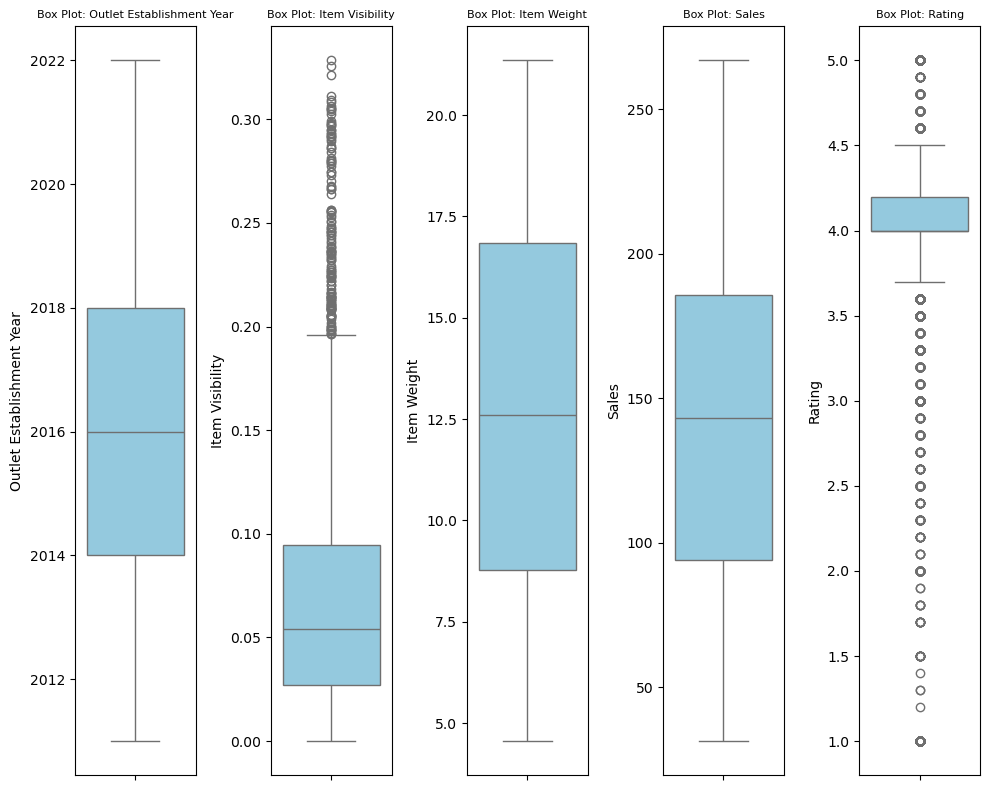

In [14]:
num_cols = df.select_dtypes(include = 'number').columns.to_list()

fig, axes = plt.subplots(1, 5, figsize=(10, 8))
axes = axes.flatten()  # Flatten 2x2 grid into 1D array for easy iteration

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(f'Box Plot: {col}', fontsize=8)
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

As per the above box plots i found 2 numerical features have outliers, those are `Item Visibility` and `Rating` columns

In [15]:
df.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T.round(2)

,count,mean,std,min,1%,5%,25%,50%,75%,90%,95%,99%,max
Outlet Establishment Year,8523.0,2016.45,3.19,2011.00,2011.00,2011.00,2014.00,2016.00,2018.00,2022.00,2022.00,2022.00,2022.00
Item Visibility,8523.0,0.07,0.05,0.00,0.00,0.00,0.03,0.05,0.09,0.14,0.16,0.23,0.33
Item Weight,7060.0,12.86,4.64,4.56,5.15,5.94,8.77,12.60,16.85,19.35,20.25,20.85,21.35
Sales,8523.0,140.99,62.28,31.29,35.06,42.52,93.83,143.01,185.64,231.20,250.77,263.02,266.89
Rating,8523.0,3.97,0.61,1.00,1.00,3.00,4.00,4.00,4.20,4.50,4.99,5.00,5.00


In [16]:
# Checking %ge of items are outliers on specific features
Q1_1 = df['Item Visibility'].quantile(0.25)
Q3_1 = df['Item Visibility'].quantile(0.75)
IQR_1 = Q3_1 - Q1_1

lb = Q1_1 - 1.5 * IQR_1
ub= Q3_1 + 1.5 * IQR_1

outlier_Item_Visibility = (df['Item Visibility'] < lb) | (df['Item Visibility'] > ub)
outlier_pct_Item_Visibility = (outlier_Item_Visibility.sum()/len(df))*100
print("Outlier percentge of Item Visibility column:",outlier_pct_Item_Visibility.round(2))

Outlier percentge of Item Visibility column: 1.69


In [17]:
Q1_1 = df['Rating'].quantile(0.25)
Q3_1 = df['Rating'].quantile(0.75)
IQR_1 = Q3_1 - Q1_1

lb = Q1_1 - 1.5 * IQR_1
ub= Q3_1 + 1.5 * IQR_1

outlier_Rating = (df['Rating'] < lb) | (df['Rating'] > ub)
outlier_pct_Rating = (outlier_Rating.sum()/len(df))*100
print("Outlier percentge of Rating column:",outlier_pct_Rating.round(2))

Outlier percentge of Rating column: 22.66


In [20]:
# Missing values in the Item weight column are filling with average of existing values
df['Item Weight'] = df['Item Weight'].fillna(df['Item Weight'].mean())

## Task 2.4: Ensuring similar information is presented

In [30]:
# Checking on each Categorical feature and fixing the similarity

In [18]:
df['Item Fat Content'].unique()

array(['Regular', 'Low Fat', 'low fat', 'LF', 'reg'], dtype=object)

`Item Fat Content` feature has similar classification such as `Low Fat = low fat = LF` and `Regular = reg`

In [19]:
# Fixing Item Fat Content similarity
df['Item Fat Content'] = df['Item Fat Content'].replace({'low fat':'Low Fat', 'LF':'Low Fat', 'reg':'Regular'})
df['Item Fat Content'].unique()

array(['Regular', 'Low Fat'], dtype=object)

There are no other object columns have similarity values

# Task 2 - Summary:
- There are **1463** records are missing in the `Item Weight` feature. No outliers existed for this feature and filled empty values with average of existing values.
- Didn't found any duplicated records.
- Found two numerical features have outliers, which are `Item Visibility` and `Rating`. The percentage of outliers founded that **22.66%** on `Rating` column and **1.69%** on `Item Visibility` column.
- `Item Fat Content` feature has similar categories, which are fixed.

## Objective 3
# Finding out What is better Sales performance

## Task 3.1: Types of Products which are selling more

In [20]:
dfg1 = df.groupby('Item Type').agg(
    Total_sales=('Sales','sum'),
    count=('Item Type','count')
).round(2).sort_values(by='count',ascending=False)
print(dfg1)
print("-"*100)
print(f"{dfg1.index[0]} are selling more of {int(dfg1.iloc[0]['count'])} and total sales of Rs.{dfg1.iloc[0]['Total_sales']}")

                       Total_sales  count
Item Type                                
Fruits and Vegetables    178124.08   1232
Snack Foods              175433.92   1200
Household                135976.53    910
Frozen Foods             118558.88    856
Dairy                    101276.46    682
Canned                    90706.73    649
Baking Goods              81894.74    648
Health and Hygiene        68025.84    520
Soft Drinks               58514.17    445
Meat                      59449.86    425
Breads                    35379.12    251
Hard Drinks               29334.68    214
Others                    22451.89    169
Starchy Foods             21880.03    148
Breakfast                 15596.70    110
Seafood                    9077.87     64
----------------------------------------------------------------------------------------------------
Fruits and Vegetables are selling more of 1232 and total sales of Rs.178124.08


## Task 3.2: Types of Outlets which are performing better

In [21]:
dfg2 = df.groupby("Outlet Type").agg(
    Total_Sales = ('Sales','sum'),
    count = ('Outlet Type','count')
).round(2).sort_values(by='Total_Sales',ascending=False)
dfg2['Average Sales'] = (dfg2['Total_Sales']/dfg2['count']).round(2)
dfg2

,Total_Sales,count,Average Sales
Outlet Type,,,
Supermarket Type1,787549.89,5577,141.21
Grocery Store,151939.15,1083,140.29
Supermarket Type2,131477.78,928,141.68
Supermarket Type3,130714.67,935,139.80


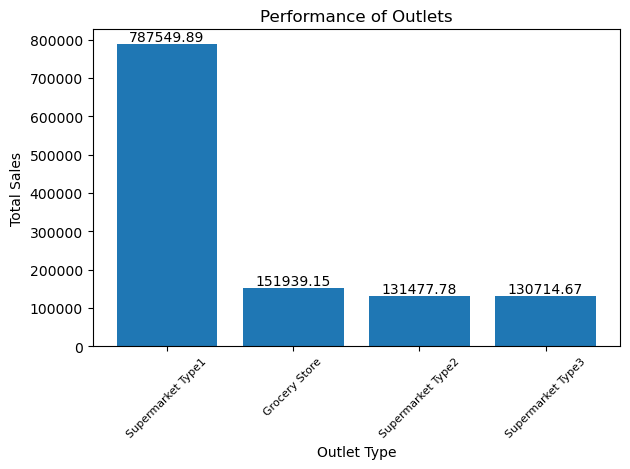

In [22]:
x = dfg2.index.to_list()
y = dfg2['Total_Sales'].to_list()

bars = plt.bar(x, y)
plt.xlabel('Outlet Type')
plt.ylabel('Total Sales')
plt.title('Performance of Outlets')
plt.xticks(rotation=45, fontsize=8)
plt.bar_label(bars,fmt='%.2f')
plt.tight_layout()

plt.show()

## Task 3.3: Ensuring whether product visibility, weight, ratings and outlet characteristics are connected with Sales

In [23]:
dfg3 = df.groupby('Outlet Type')['Sales'].mean()
dfg3

Outlet Type
Grocery Store        140.294690
Supermarket Type1    141.213895
Supermarket Type2    141.678638
Supermarket Type3    139.801791
Name: Sales, dtype: float64

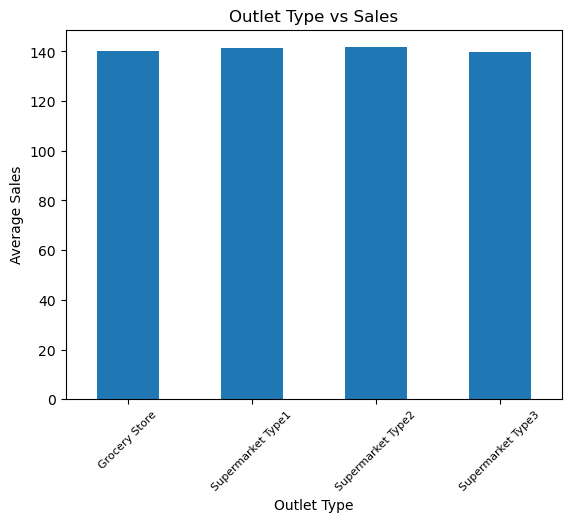

In [24]:
dfg3.plot(kind='bar')
plt.ylabel('Average Sales')
plt.xticks(rotation=45, fontsize=8)
plt.title('Outlet Type vs Sales')
plt.show()

In [25]:
corr = df.corr(numeric_only=True)['Sales'].sort_values(ascending=False)
print(corr)

Sales                        1.000000
Item Weight                  0.027141
Rating                       0.011329
Outlet Establishment Year   -0.000654
Item Visibility             -0.001315
Name: Sales, dtype: float64


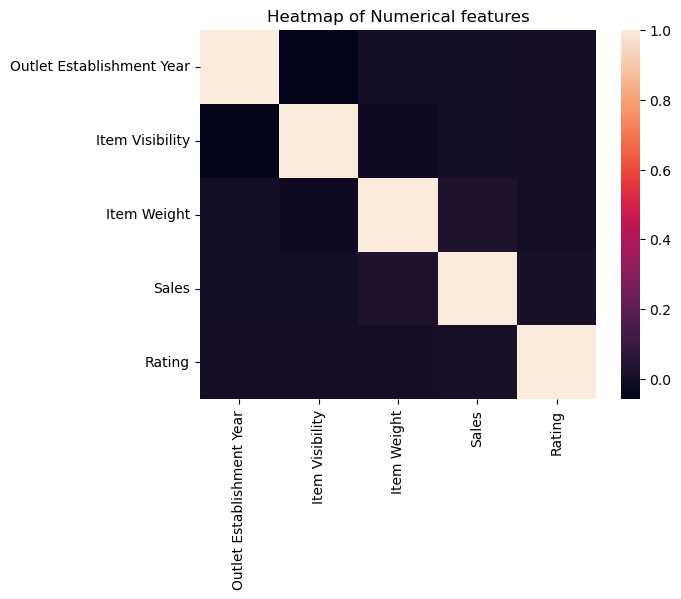

In [26]:
sns.heatmap(df.corr(numeric_only=True))
plt.title('Heatmap of Numerical features')
plt.show()

## Task 3.4: Comparing better-performing and lower-performing products and outlets

In [27]:
dfg4 = df.pivot_table(
    values = 'Sales',
    index = 'Item Type',
    columns = 'Outlet Type',
    aggfunc = 'sum'
).round(2)

dfg4.style.highlight_max(axis=0, color='lightgreen')
dfg4.style.highlight_min(axis=0, color ='lightcoral')

dfg4

Outlet Type,Grocery Store,Supermarket Type1,Supermarket Type2,Supermarket Type3
Item Type,,,,
Baking Goods,10747.24,53665.46,8594.20,8887.84
Breads,4832.94,22490.81,3539.40,4515.96
Breakfast,2793.51,9632.65,1552.61,1617.92
Canned,10079.90,59649.31,10852.47,10125.05
Dairy,13539.34,67179.69,10638.94,9918.48
Frozen Foods,13750.44,79348.38,13253.72,12206.35
Fruits and Vegetables,21423.41,117431.99,18967.29,20301.39
Hard Drinks,2812.54,19610.76,3609.12,3302.26
Health and Hygiene,8964.02,44050.75,7339.92,7671.14


In [28]:
result_df = pd.DataFrame({
    'Max Item': dfg4.idxmax(),
    'Max Sales': dfg4.max(),
    'Min Item': dfg4.idxmin(),
    'Min Sales': dfg4.min()
})
result_df

,Max Item,Max Sales,Min Item,Min Sales
Outlet Type,,,,
Grocery Store,Fruits and Vegetables,21423.41,Seafood,1438.16
Supermarket Type1,Fruits and Vegetables,117431.99,Seafood,5681.52
Supermarket Type2,Snack Foods,20003.24,Seafood,1089.99
Supermarket Type3,Fruits and Vegetables,20301.39,Seafood,868.20


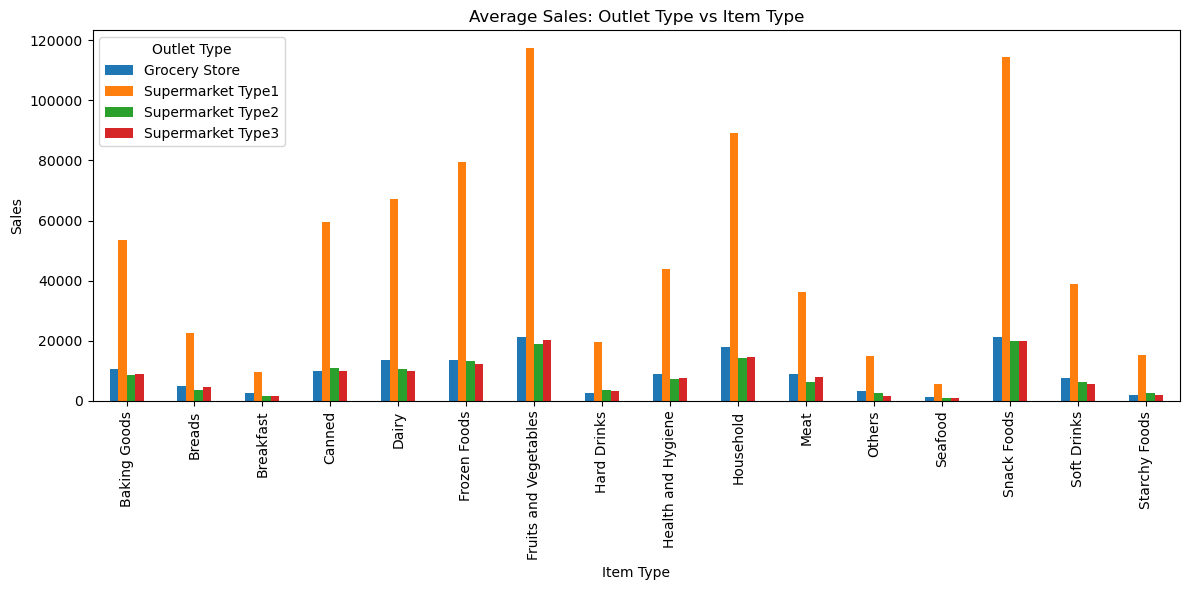

In [29]:
dfg4.plot(kind='bar', figsize=(12,6))
plt.title('Average Sales: Outlet Type vs Item Type')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()

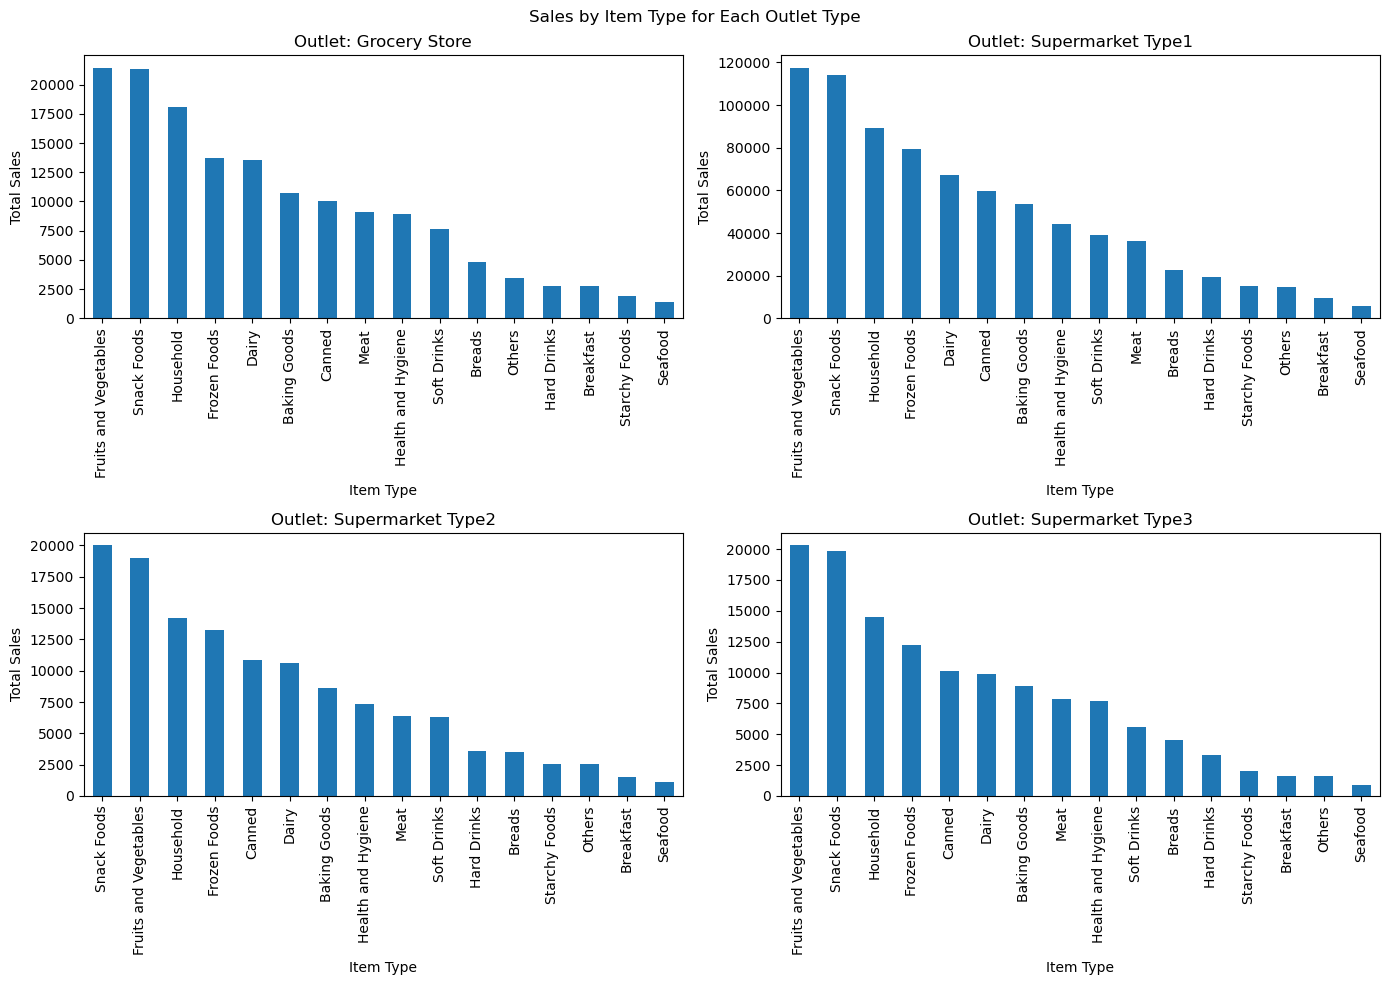

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.flatten()

for i, outlet in enumerate(dfg4.columns):
    dfg4[outlet].sort_values(ascending=False).plot(kind='bar', ax=axes[i])
    axes[i].set_title(f'Outlet: {outlet}')
    axes[i].set_ylabel('Total Sales')
    axes[i].set_xlabel('Item Type')
    axes[i].tick_params(axis='x', rotation=90)

plt.suptitle('Sales by Item Type for Each Outlet Type')
plt.tight_layout()
plt.show()

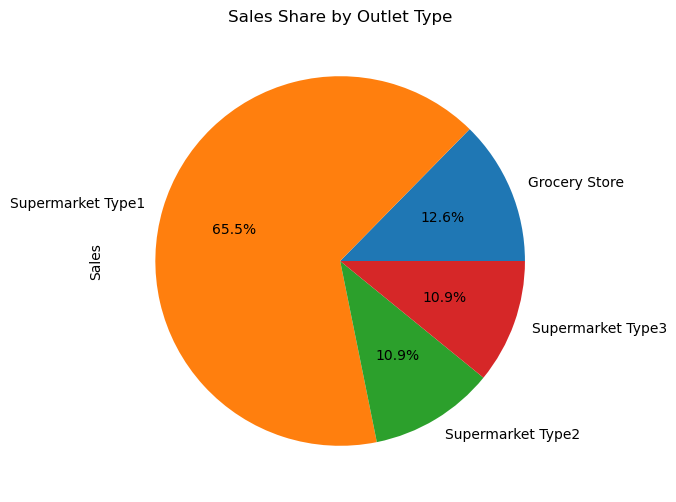

In [31]:
dfg4_pie = df.groupby('Outlet Type')['Sales'].sum()
dfg4_pie.plot(
    kind = 'pie',
    autopct = '%1.1f%%',
    figsize = (6,6)
)
plt.title('Sales Share by Outlet Type')
plt.show()

# Task 3 - Summary:
- There are the products `Fruits and Vegetables` are selling more of **1232** and total sales of **Rs.178124.08**.
- The `Supermarket Type1` is performing better in sales and is of Rs. **787549.89**. It is **65.5%** over all Outlets.
- There is no impact on `Sales` be connection with `Product Visibility, Rating, Weight and Outlet charactristics`.
- Highest sales observed on `Fruits and Vegetables` from all type Outlets and Lowest sales observed on `Seafood`.
- One extent Highest sales observed on `Snack Foods` from `Supermarket Type2`.

## Objective 4
# Helping Management Make Better Business Decisions

## Task 4.1: Identifying the products that are contributing more to sales

- Apart from all product types, `Fruits and Vegetables` are contributing more sales in Blinkit. Followed by `Snack Foods` also observed that have more sales.

In [32]:
dfg5 = df.groupby('Item Type')['Sales'].agg(['sum','mean']).round(2).sort_values(by='sum',ascending=False)
dfg5

,sum,mean
Item Type,,
Fruits and Vegetables,178124.08,144.58
Snack Foods,175433.92,146.19
Household,135976.53,149.42
Frozen Foods,118558.88,138.50
Dairy,101276.46,148.50
Canned,90706.73,139.76
Baking Goods,81894.74,126.38
Health and Hygiene,68025.84,130.82
Meat,59449.86,139.88


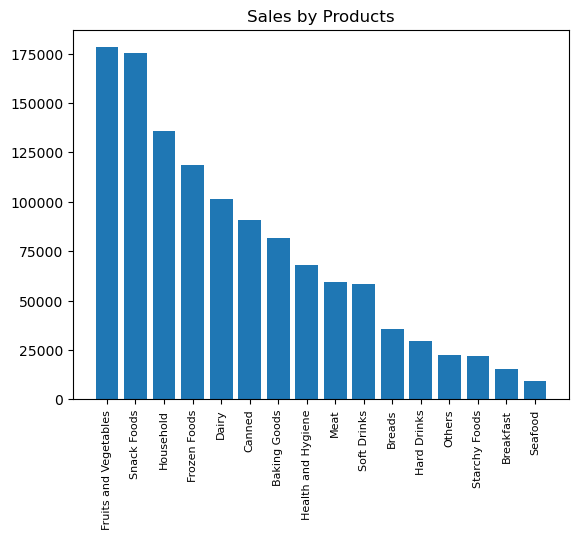

In [33]:
plt.bar(dfg5.index.tolist(), dfg5['sum'].tolist())
plt.title('Sales by Products')
plt.xticks(rotation=90,fontsize=8)
plt.show()

## Task 4.2: Identifying the outlets and locations that are performing better

- Among all Outlet types, more sales happened in `Supermarket Type1` from all Outlet Locations.
- As per the observation, in `Tier 3` location, all kind of Outlet services available, as no outlet services observed in remaining locations.

In [34]:
dfg6 = df.pivot_table(
    values = 'Sales',
    index = 'Outlet Type',
    columns = 'Outlet Location Type',
    aggfunc = 'sum',
    fill_value = 0
).round(2)

dfg6

Outlet Location Type,Tier 1,Tier 2,Tier 3
Outlet Type,,,
Grocery Store,73807.58,0.00,78131.57
Supermarket Type1,262590.23,393150.65,131809.02
Supermarket Type2,0.00,0.00,131477.78
Supermarket Type3,0.00,0.00,130714.67


In [35]:
dfg7 = df.pivot_table(
    values = 'Sales',
    index = 'Item Type',
    columns = 'Outlet Location Type',
    aggfunc = 'sum'
).round(2)
dfg7

Outlet Location Type,Tier 1,Tier 2,Tier 3
Item Type,,,
Baking Goods,23011.99,26640.51,32242.24
Breads,9785.07,11561.74,14032.31
Breakfast,4150.56,4847.30,6598.84
Canned,24549.26,31824.95,34332.52
Dairy,29915.50,31814.94,39546.02
Frozen Foods,34126.16,39024.58,45408.14
Fruits and Vegetables,50125.99,57268.38,70729.71
Hard Drinks,7323.52,9793.70,12217.46
Health and Hygiene,18199.38,21580.49,28245.97


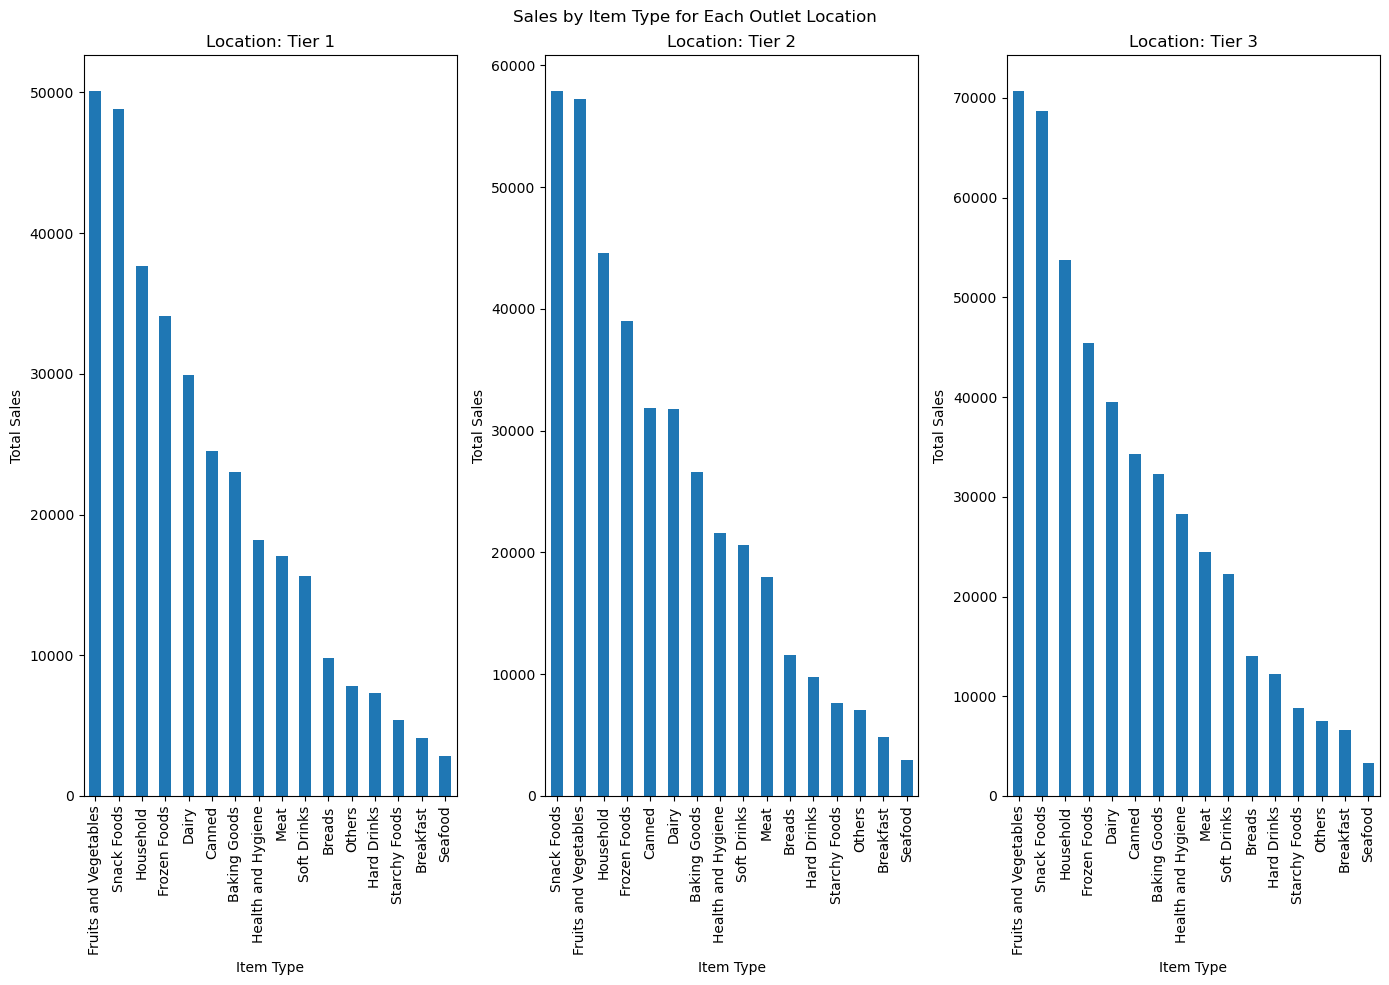

In [157]:
fig, axes = plt.subplots(1, 3, figsize=(14,10))
axes = axes.flatten()

for i, location in enumerate(dfg7.columns):
    dfg7[location].sort_values(ascending=False).plot(kind='bar', ax=axes[i])
    axes[i].set_title(f'Location: {location}')
    axes[i].set_ylabel('Total Sales')
    axes[i].set_xlabel('Item Type')
    axes[i].tick_params(axis='x', rotation=90)

plt.suptitle('Sales by Item Type for Each Outlet Location')
plt.tight_layout()
plt.show()

In [36]:
result_df2 = pd.DataFrame({
    'Max Item': dfg7.idxmax(),
    'Max Sales': dfg7.max(),
    'Min Item': dfg7.idxmin(),
    'Min Sales': dfg7.min()
})
result_df2

,Max Item,Max Sales,Min Item,Min Sales
Outlet Location Type,,,,
Tier 1,Fruits and Vegetables,50125.99,Seafood,2866.92
Tier 2,Snack Foods,57930.71,Seafood,2952.39
Tier 3,Fruits and Vegetables,70729.71,Seafood,3258.56


## Task 4.3: Identifying products, outlets, and areas where performance can be improve

- As per previous analysis, clearly observed that extreme sales happened on products, which are `Fruits and Vegetables` and `Snack Foods`, majorly happened in `Supermarket Type1` outlets at all locations.
- Extend the business in `Tier3` locations would be suitable option to increase more Sales and Performance.

## Task 4.4: Practical suggestions to improve sales and overall business performance

- Extending the buisiness in `Tier 3` locations are risk free, however it is proved that majority of sales happened in it.
- Start with less stores in `Tier 1` and `Tier 2` locations would be a good move to improve, as all products at all available locations, average sales are equal.
- Offering bulk items with some discount on all products at far locations is a reasonable option to improve Sales.
- Providing coupons for certain amount of purchasings, will improve to avoid churn.